In [1]:
%run sem2.py

In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import matplotlib.pyplot as plt
import time

In [3]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [4]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60, ex1, ex2 , ex3 ~ Normal(0,1)"
model = sem2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(2000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 6.7226, s1: 7.2578, s2: 1.0703
Iter 100 | loss: 4.2649, s1: 6.0531, s2: 3.5764
Iter 200 | loss: 2.9438, s1: 5.3960, s2: 4.9043
Iter 300 | loss: 2.2422, s1: 4.7626, s2: 5.0408
Iter 400 | loss: 1.8116, s1: 3.9069, s2: 4.1907
Iter 500 | loss: 1.5217, s1: 3.4129, s2: 3.7824
Iter 600 | loss: 1.3841, s1: 2.8312, s2: 2.8942
Iter 700 | loss: 1.2835, s1: 2.8612, s2: 3.1554
Iter 800 | loss: 1.4586, s1: 2.8795, s2: 2.8418
Iter 900 | loss: 1.1313, s1: 2.5534, s2: 2.8443
Iter 1000 | loss: 1.4138, s1: 2.7243, s2: 2.6209
Iter 1100 | loss: 1.4736, s1: 2.8549, s2: 2.7624
Iter 1200 | loss: 1.4302, s1: 2.8338, s2: 2.8072
Iter 1300 | loss: 1.3324, s1: 2.5965, s2: 2.5282
Iter 1400 | loss: 1.1967, s1: 2.5750, s2: 2.7566
Iter 1500 | loss: 1.6345, s1: 2.9429, s2: 2.6167
Iter 1600 | loss: 1.2502, s1: 2.7910, s2: 3.0817
Iter 1700 | loss: 1.3797, s1: 2.7625, s2: 2.7655
Iter 1800 | loss: 1.5527, s1: 2.8500, s2: 2.5945
Iter 1900 | loss: 1.2792, s1: 2.5803, s2: 2.6021
Iter 2000 | loss: 1.4767, s1: 2.

In [6]:
beta = [model.layer[node].weight[0][0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]

[1.0, 2.1297399848589733, 1.8198121415744175]

In [7]:
# Linear factor model (same as lavaan package example)
# Loss function: log-likelihood
formula_eps = "ex1, ex2, ex3, ey1, ey2, ey3, ey4, ey5, ey6, ey7, ey8, edem60, edem65 ~ Normal(0,1);" 
formula_epscov = "e15, e24, e26, e37, e48, e68 ~ Normal(0,1);"
formula_end = "ind60 ~ Normal(0,1); dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26 + e68; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
formula2 = formula_eps + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [8]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]
sample_cov = torch.cov(torch.t(x))

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [9]:
# Maximum likelihood (use sample from model to estimate variance)
model2 = sem2(formula2)
observed_index = [list(model2.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model2.parameters(), lr=5e-2)
model2.train()
niter = 1000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model2(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    # loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model2.layer["x1"].weight[0][0]
    dem60_scale = model2.layer["y1"].weight[0][0]
    dem65_scale = model2.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model2.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model2.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model2.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 518.7571, s1: 2.8484, s2: 2.7435
[ 1.85055888 -0.5021013  -0.05981668]
Iter 1000 | loss: 21.3485, s1: 2.8484, s2: 2.7435
[1.50672829 0.56475919 0.83923018]


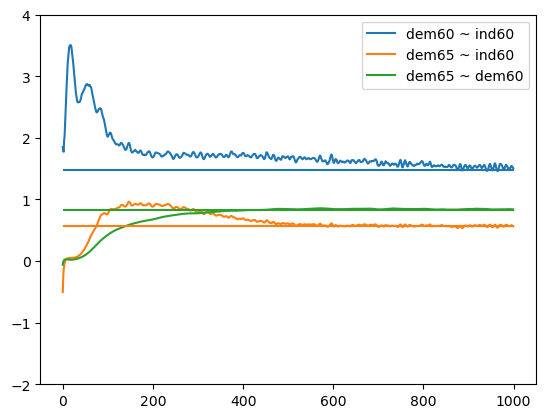

In [10]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [11]:
# Energy loss minimization (100 * data size to estimate loss, normalize x first)
model3 = sem2(formula2, device = "cpu")
x_normalized = x_normalized.to("cpu")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model3.parameters(), lr=1e-2)
model3.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model3(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model3.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model3.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model3.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model3.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model3.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model3.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.1887, s1: 9.4531, s2: 2.5289
[-2.30917025 -2.17300916  0.0399417 ]
Iter 1000 | loss: 2.1959, s1: 4.4420, s2: 4.4922
[2.00475907 1.12950122 0.81930476]
Iter 2000 | loss: 2.2015, s1: 4.4629, s2: 4.5228
[1.898736   0.79240131 0.78192961]
Iter 3000 | loss: 2.2021, s1: 4.4463, s2: 4.4884
[1.78341293 0.65311986 0.84468508]


In [12]:
# Run time of one iteration
start = time.time()
sample = model3(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

0.01797008514404297


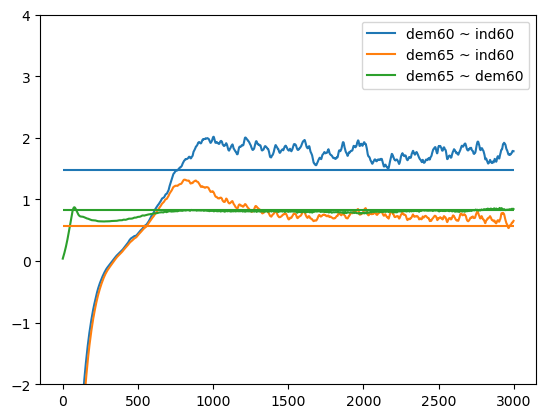

In [13]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [14]:
# Energy loss minimization on GPU
model4 = sem2(formula2, device = "mps")
x_normalized = x_normalized.to("mps")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model4.parameters(), lr=1e-2)
model4.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model4(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model4.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model4.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model4.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model4.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model4.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model4.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.7127, s1: 9.8949, s2: 2.3644
[ 0.02204134  0.11507673 -1.11589956]
Iter 1000 | loss: 2.1791, s1: 4.4245, s2: 4.4907
[1.86548638 0.82277715 0.71194059]
Iter 2000 | loss: 2.2162, s1: 4.4396, s2: 4.4467
[1.75680768 0.75075197 0.8199954 ]
Iter 3000 | loss: 2.1958, s1: 4.4384, s2: 4.4852
[1.70278513 0.741229   0.82079214]


In [15]:
# Run time of one iteration
start = time.time()
sample = model4(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

0.02832794189453125


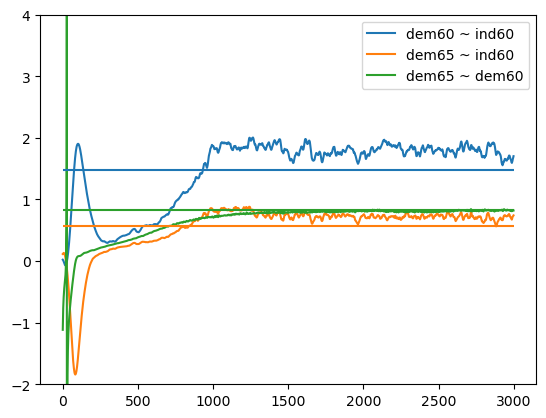

In [16]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()